In [4]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings('ignore')

har = fetch_openml(data_id=1478, as_frame=True, parser='liac-arff')
X_full = har.data.astype(float)
y_full = har.target.astype(int)

label_map = {
    1: 'WALKING',
    2: 'WALKING_UPSTAIRS',
    3: 'WALKING_DOWNSTAIRS',
    4: 'SITTING',
    5: 'STANDING',
    6: 'LAYING',
}

np.random.seed(42)
n_samples = len(X_full)
subjects_full = pd.Series(
    np.repeat(np.arange(1, 31), n_samples // 30 + 1)[:n_samples]
)

X_train, X_test = X_full.iloc[:7352], X_full.iloc[7352:]
y_train, y_test = y_full.iloc[:7352], y_full.iloc[7352:]

print(f'Общий размер датасета: {X_full.shape}')
print(f'Количество уникальных субъектов: {subjects_full.nunique()}')


Общий размер датасета: (10299, 561)
Количество уникальных субъектов: 30


Количество пропусков в данных: 0
Минимальное значение признаков: -1.00, Максимальное: 1.00

Распределение классов активностей:
Class
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64


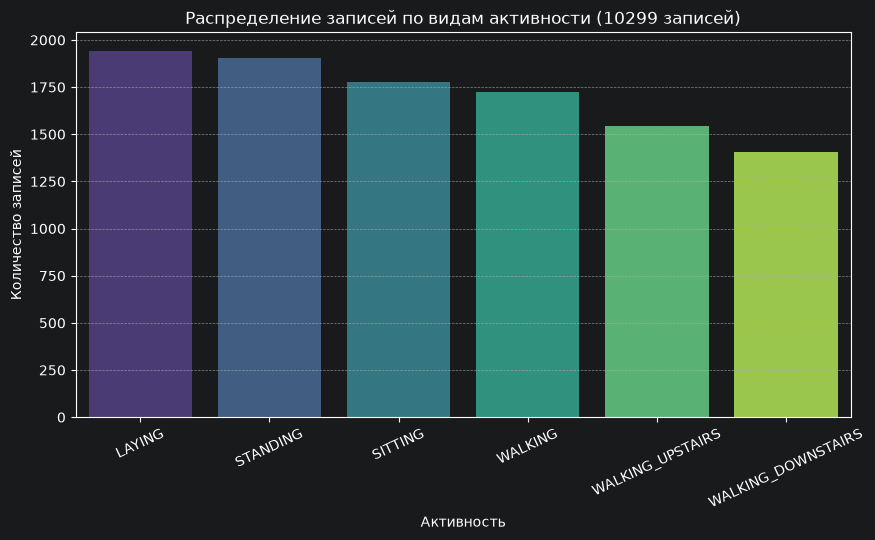

In [5]:
print(f'Количество пропусков в данных: {X_full.isnull().sum().sum()}')
print(
    f'Минимальное значение признаков: {X_full.min().min():.2f}, Максимальное:'
    f' {X_full.max().max():.2f}'
)

activity_counts = y_full.map(label_map).value_counts()
print('\nРаспределение классов активностей:')
print(activity_counts)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=activity_counts.index, y=activity_counts.values, palette='viridis'
)
plt.title('Распределение записей по видам активности (10299 записей)')
plt.xlabel('Активность')
plt.ylabel('Количество записей')
plt.xticks(rotation=25)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


Компонент для объяснения 90% дисперсии: 65 из 561
Компонент для объяснения 95% дисперсии: 104 из 561


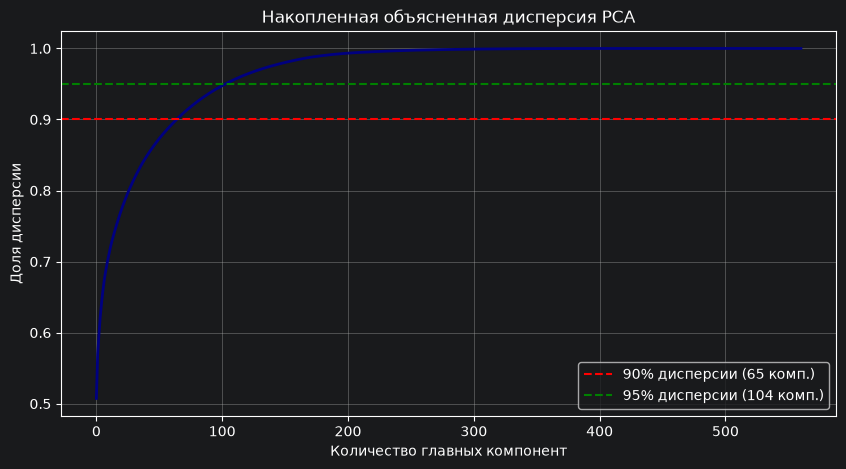

KNN без PCA (561 признак)      | GroupKFold Accuracy: 0.8984
PCA (50 комп.) + KNN           | GroupKFold Accuracy: 0.8764
PCA (100 комп.) + KNN          | GroupKFold Accuracy: 0.8909
PCA (150 комп.) + KNN          | GroupKFold Accuracy: 0.8950


In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_full)

pca_full = PCA().fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

n_90 = np.argmax(cum_var >= 0.90) + 1
n_95 = np.argmax(cum_var >= 0.95) + 1
print(f'Компонент для объяснения 90% дисперсии: {n_90} из {X_full.shape[1]}')
print(f'Компонент для объяснения 95% дисперсии: {n_95} из {X_full.shape[1]}')

plt.figure(figsize=(10, 5))
plt.plot(cum_var, linewidth=2, color='navy')
plt.axhline(
    y=0.90, color='r', linestyle='--', label=f'90% дисперсии ({n_90} комп.)'
)
plt.axhline(
    y=0.95, color='g', linestyle='--', label=f'95% дисперсии ({n_95} комп.)'
)
plt.title('Накопленная объясненная дисперсия PCA')
plt.xlabel('Количество главных компонент')
plt.ylabel('Доля дисперсии')
plt.legend()
plt.grid(True)
plt.show()

gkf = GroupKFold(n_splits=5)

for n_comp in [None, 50, 100, 150]:
  if n_comp is None:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=7)),
    ])
    label = 'KNN без PCA (561 признак)'
  else:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=n_comp)),
        ('knn', KNeighborsClassifier(n_neighbors=7)),
    ])
    label = f'PCA ({n_comp} комп.) + KNN'

  scores = cross_val_score(
      pipe, X_full, y_full, groups=subjects_full, cv=gkf, scoring='accuracy'
  )
  print(f'{label:30s} | GroupKFold Accuracy: {scores.mean():.4f}')


In [7]:
gkf = GroupKFold(n_splits=5)

models = {
    'KNN (PCA=100)': Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=100)),
        ('clf', KNeighborsClassifier(n_neighbors=7, metric='manhattan')),
    ]),
    'SVM (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf', C=10, gamma='scale', random_state=42)),
    ]),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=12, min_samples_split=5, random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=150, max_depth=20, n_jobs=-1, random_state=42
    ),
}

cv_results = []

for name, model in models.items():
  acc_scores = cross_val_score(
      model,
      X_full,
      y_full,
      groups=subjects_full,
      cv=gkf,
      scoring='accuracy',
      n_jobs=-1,
  )
  f1_scores = cross_val_score(
      model,
      X_full,
      y_full,
      groups=subjects_full,
      cv=gkf,
      scoring='f1_macro',
      n_jobs=-1,
  )

  cv_results.append({
      'Модель': name,
      'GroupKFold Accuracy (mean)': round(acc_scores.mean(), 4),
      'Accuracy (std)': round(acc_scores.std(), 4),
      'F1-macro (mean)': round(f1_scores.mean(), 4),
  })

results_df = pd.DataFrame(cv_results).sort_values(
    by='GroupKFold Accuracy (mean)', ascending=False
)
print('--- Сравнение моделей на кросс-валидации по субъектам (GroupKFold) ---')
print(results_df.to_string(index=False))


--- Сравнение моделей на кросс-валидации по субъектам (GroupKFold) ---
       Модель  GroupKFold Accuracy (mean)  Accuracy (std)  F1-macro (mean)
    SVM (RBF)                      0.9580          0.0146           0.9578
Random Forest                      0.9387          0.0188           0.9377
KNN (PCA=100)                      0.8937          0.0227           0.8937
Decision Tree                      0.8694          0.0175           0.8644


Лучшая модель: SVM (RBF)
Точность на отложенной тестовой выборке (Accuracy): 0.9549
Macro F1-score на тесте: 0.9540

Отчет по классификации:
                    precision    recall  f1-score   support

           WALKING       0.95      0.97      0.96       496
  WALKING_UPSTAIRS       0.93      0.96      0.95       471
WALKING_DOWNSTAIRS       0.97      0.92      0.94       420
           SITTING       0.96      0.90      0.93       491
          STANDING       0.91      0.97      0.94       532
            LAYING       1.00      1.00      1.00       537

          accuracy                           0.95      2947
         macro avg       0.96      0.95      0.95      2947
      weighted avg       0.96      0.95      0.95      2947



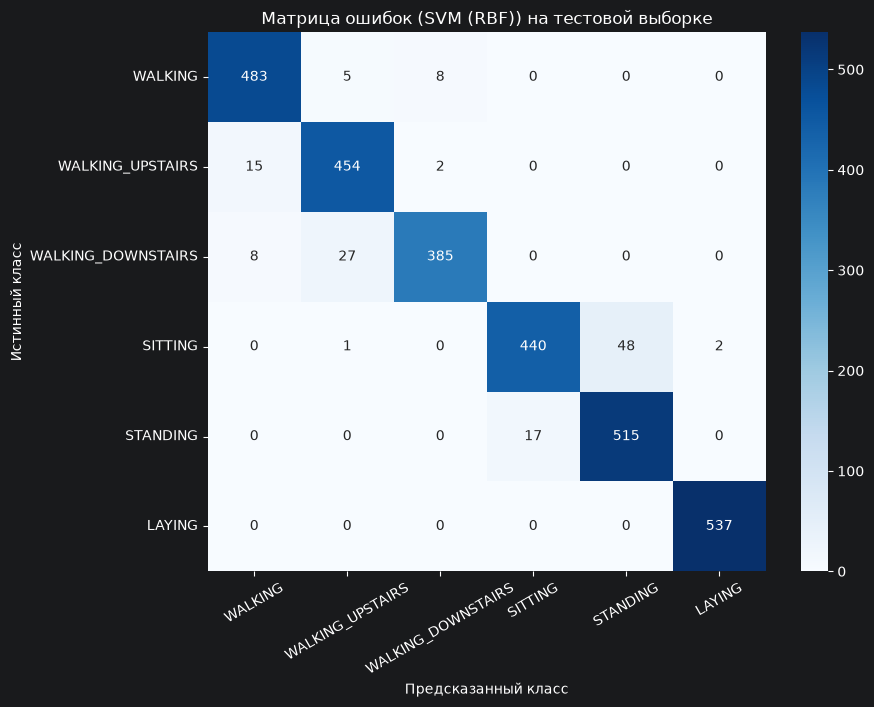

In [8]:
best_model_name = results_df.iloc[0]['Модель']
best_model = models[best_model_name]

best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

test_acc = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average='macro')

print(f'Лучшая модель: {best_model_name}')
print(f'Точность на отложенной тестовой выборке (Accuracy): {test_acc:.4f}')
print(f'Macro F1-score на тесте: {test_f1:.4f}\n')

target_names = [label_map[i] for i in sorted(label_map.keys())]
print('Отчет по классификации:')
print(classification_report(y_test, y_pred, target_names=target_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names,
)
plt.title(f'Матрица ошибок ({best_model_name}) на тестовой выборке')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.xticks(rotation=30)
plt.yticks(rotation=0)
plt.show()
